# Descriptive Context Analysis

Analyze the dataframe with the paragraphs from the legal court data. The options to check:
- Paragraph-to-Paragraph within-documents
- Paragraph-to-Paragraph cross-documents
- Compute normalized centroid - semantic topology of paragraph classes
- Inter-class cohesion
- Inter-class separation
- K-nearest paragraphs
- Silhouette score

In [14]:
import numpy as np
import pandas as pd
import functional as pyf
import torch

In [4]:
from google.cloud import storage, bigquery

In [1]:
from datasets import Dataset

In [2]:
DATASET_PATH = "legal_paragraphs_dataset_v2.parquet"
ENCODER_PATH = "bge_model/bge-small-uk-law-v1_1/final/encoder"
TOKENIZER_PATH = "bge_model/bge-small-uk-law-v1_1/final/tokenizer"

In [13]:
BUCKET_NAME = "court_data_2024_structured"
BUCKET_FILE_PATH = "document_text_parsing/info_version_9/2/{doc_id}/classification.parquet"

In [3]:
paragraph_dataset_mini = [
    "116062204", "116075685", "116080900", "116084352", "116084886", "116099338", "116102314", "116105977", "116106432", "116109598", "116110555", "116116081", "116118921", "116120654", "116121714", "116125191", "116126076", "116127831", "116141779", "116142769", "116149190", "116150283", "116167789", "116168634", "116170057", "116170822", "116192026", "116194637", "116196887", "116197578", "116199866", "116204676", "116213690", "116214232", "116220471", "116221948", "116226431", "116229939", "116232414", "116233794", "116245112", "116246991", "116248468", "116252607", "116253514", "116256069", "116257159", "116259036", "116260246", "116261015", "116261263", "116270112", "116277632", "116278949", "116283678", "116285648", "116289180", "116308208", "116310154", "116320626", "116321603", "116336690", "116339406", "116344031", "116350541", "116350825", "116358099", "116359089", "116376162", "116377931", "116385451", "116398308", "116410200", "116410462", "116414218", "116432495", "116434259", "116442566", "116462199", "116588653", "116681882", "116764649", "116780853", "116790074", "116794466", "116972204", "117069850", "117125134", "117130242", "117230819", "117251852", "117420480", "117440182", "117456818", "117460145", "117464049", "117489745", "117516936", "117556435"
]

### Downloading document paragraphs from the Cloud Storage

In [6]:
from pathlib import Path

In [5]:
bq_client = bigquery.Client()
storage_client = storage.Client()

In [21]:
def download_necessary_docs(doc_list: list):
    local_doc_folder = Path("doc_artifacts")
    if not local_doc_folder.exists():
        local_doc_folder.mkdir()

    data_bucket = storage_client.bucket(BUCKET_NAME)
    pyf.seq(doc_list).map(lambda doc_id: BUCKET_FILE_PATH.format(doc_id=doc_id)) \
                   .for_each(lambda blob_path: data_bucket.blob(blob_path).download_to_filename(local_doc_folder / (blob_path.split("/")[-2] + ".parquet")))

In [22]:
download_necessary_docs(paragraph_dataset_mini)

### Loading model for further usage

In [33]:
from sentence_transformers import models, SentenceTransformer

Fixing encoder model path

In [34]:
search_roots = (Path.cwd(), *Path.cwd().parents)
model_base = next(
    (
        base
        for root in search_roots
        for base in (root, root / "src" / "legal_data_doc_parts")
        if (base / ENCODER_PATH).is_dir() and (base / TOKENIZER_PATH).is_dir()
    ),
    None,
)
if model_base is None:
    raise FileNotFoundError(
        f"Could not locate {ENCODER_PATH!r} and {TOKENIZER_PATH!r} from {Path.cwd()}"
    )

In [35]:
transformer = models.Transformer(
    str(model_base / ENCODER_PATH),
    tokenizer_name_or_path=str(model_base / TOKENIZER_PATH),
)
pooling = models.Pooling(
    transformer.get_embedding_dimension(),
    pooling_mode="mean",
)
legal_encoder = SentenceTransformer(modules=[transformer, pooling])

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /home/vegura/Projects/study/legal-data-doc-parts/src/legal_data_doc_parts/bge_model/bge-small-uk-law-v1_1/final/encoder
Key                 | Status  | 
--------------------+---------+-
pooler.dense.weight | MISSING | 
pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
The `tokenizer_name_or_path` argument is deprecated and will be removed in a future version. Please use the same path for the model and processor.


Trying to compose all documents

In [243]:
def compose_full_dataframe(doc_ids: list[str]):
    file_path_template = "doc_artifacts/{doc_id}.parquet"
    file_path_list = pyf.seq(doc_ids).map(lambda doc_id: file_path_template.format(doc_id=doc_id)).to_list()

    first_df = pd.read_parquet(file_path_list[0])
    for file_path in file_path_list[1:]:
        second_df = pd.read_parquet(file_path)
        first_df = pd.concat([first_df, second_df])
    return first_df

In [244]:
full_legal_doc_df = compose_full_dataframe(paragraph_dataset_mini)
full_legal_reasoning_doc_df = (
    full_legal_doc_df.loc[full_legal_doc_df["section"] == "reasoning"]
    .copy()
    .reset_index(drop=True)
)

In [245]:
reasoning_text_list = full_legal_reasoning_doc_df["text"].to_list()
full_paragraph_embeddings = legal_encoder.encode(
    reasoning_text_list,
    batch_size=32,
    normalize_embeddings=True,
    show_progress_bar=True,
    convert_to_numpy=True
)

Batches:   0%|          | 0/80 [00:00<?, ?it/s]

### Measuring cosine similarity

In [246]:
from sklearn.metrics.pairwise import cosine_similarity
import torch.nn.functional as F
import torch

In [247]:
def process_distances(embeddings, global_batch_size, local_batch_size, device="cuda"):
    embeddings = np.asanyarray(embeddings, dtype=np.float32)
    n = embeddings.shape[0]
    distances = np.empty((n, n), dtype=np.float32)

    with torch.inference_mode():
        for global_start in range(0, n, global_batch_size):
            global_end = min(global_start + global_batch_size, n)
            global_embeddings = torch.as_tensor(
                embeddings[global_start:global_end],
                dtype=torch.float32,
                device=device
            )
            global_embeddings = F.normalize(global_embeddings, p=2, dim=1)

            for row_start in range(global_start, global_end, local_batch_size):
                row_end = min(row_start + local_batch_size, global_end)

                row_offset_start = row_start - global_start
                row_offset_end = row_end - global_start
                x = global_embeddings[row_offset_start: row_offset_end]

                for col_start in range(row_start, n, local_batch_size):
                    col_end = min(col_start + local_batch_size, n)

                    if global_start <= col_start and col_end <= global_end:
                        y = global_embeddings[col_start - global_start: col_end - global_start]
                    else:
                        y = torch.as_tensor(
                            embeddings[col_start: col_end],
                            dtype=torch.float32,
                            device=device,
                        )

                    similarity = (x @ y.T).cpu().numpy()
                    distances[row_start:row_end, col_start:col_end] = similarity
                    distances[col_start:col_end, row_start:row_end] = similarity.T

                    del y, similarity

            del global_embeddings

        np.fill_diagonal(distances, 1.0)
        return distances

In [248]:
D = 1 - process_distances(full_paragraph_embeddings, 32, 8)
np.fill_diagonal(D, np.float32(0.0))
D[D < 0] = 0

In [249]:
D.shape

(2534, 2534)

## Plotting distance matrix as heatmap

In [250]:
import matplotlib.pyplot as plt
import seaborn as sns

<Axes: >

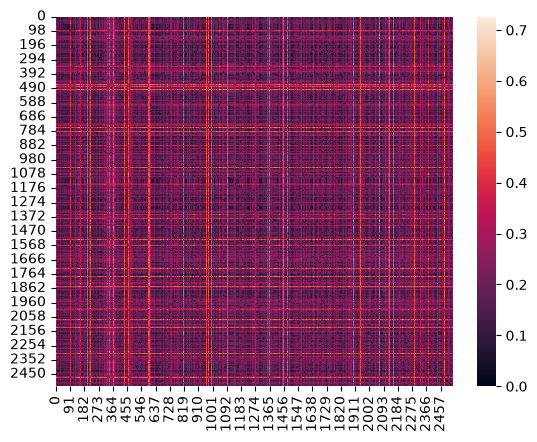

In [251]:
sns.heatmap(D)

In [252]:
from sklearn.neighbors import NearestNeighbors

In [253]:
def optimal_epsilon_plot(dist_m, min_samples):
    plt.figure(figsize=(10, 10))

    nn = NearestNeighbors(n_neighbors=min_samples, metric="precomputed")
    nn.fit(dist_m)
    distances, indicies = nn.kneighbors(dist_m)
    k_distances = distances[:, -1]
    k_distances = np.sort(k_distances)
    plt.plot(k_distances)

    plt.xlabel("Points sorted by distance")
    plt.ylabel(f"{min_samples}-NN distance")
    plt.title("k-distance Graph for DBScan")
    plt.grid(True)
    plt.show()

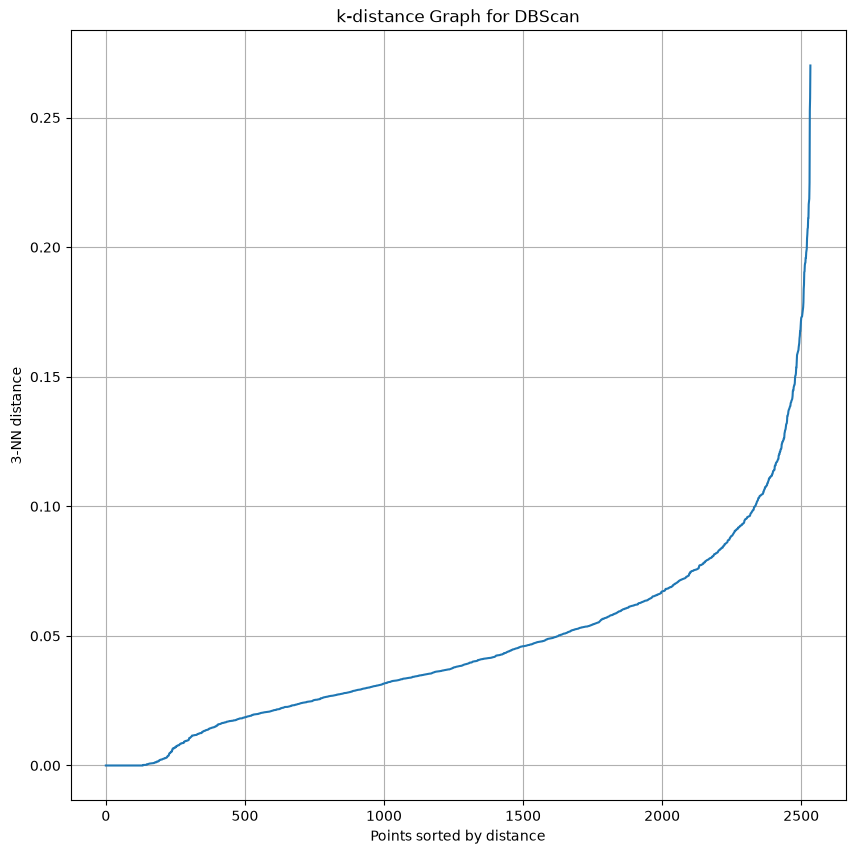

In [254]:
optimal_epsilon_plot(D, 3)

## Clustering the context similar paragraphs

In [255]:
from sklearn.cluster import DBSCAN, HDBSCAN
from sklearn.metrics import silhouette_score

In [256]:
type(D)

numpy.ndarray

In [265]:
legal_par_cluster = DBSCAN(eps=0.02, min_samples=10, metric="precomputed").fit_predict(D)
silhouette_score(D, legal_par_cluster, metric="precomputed")

-0.3164966106414795

In [266]:
legal_par_cluster

array([ 0, -1, -1, ..., -1, -1, -1], shape=(2534,))

Fetching similar paragraphs

In [267]:
full_legal_reasoning_doc_df["cluster"] = legal_par_cluster
clustered_paragraphs = (
    full_legal_reasoning_doc_df
    .loc[full_legal_reasoning_doc_df["cluster"] != -1]
    .sort_values("cluster")
)

In [268]:
full_legal_reasoning_doc_df.sort_values(by="cluster", inplace=True)
full_legal_reasoning_doc_df[full_legal_reasoning_doc_df["cluster"] != -1]

,document_id,paragraph_index,paragraph_order,numbered_text,text,section,cluster
1683,116350541,16,16,[paragraph_id=16] Відповідно до наказу Міністе...,Відповідно до наказу Міністерства охорони здор...,reasoning,0
879,116213690,36,36,[paragraph_id=36] Виходячи з вимог ст. 65 КК У...,"Виходячи з вимог ст. 65 КК України, суд призна...",reasoning,0
136,116080900,17,17,[paragraph_id=17] Відповідно до положень ч. 2 ...,Відповідно до положень ч. 2 ст. 302 КПК Україн...,reasoning,0
36,116062204,52,52,"[paragraph_id=52] Крім того, суд бере до уваги...","Крім того, суд бере до уваги той факт, що узго...",reasoning,0
535,116127831,34,34,[paragraph_id=34] Відповідно до вимог ч.4 ст.4...,Відповідно до вимог ч.4 ст.469 КПК України уго...,reasoning,0
...,...,...,...,...,...,...,...
2276,117420480,16,16,"[paragraph_id=16] ОСОБА_4 , у точно невстановл...","ОСОБА_4 , у точно невстановлений день та час, ...",reasoning,11
1691,116350541,24,24,[paragraph_id=24] Зазначені дії ОСОБА_2 кваліф...,Зазначені дії ОСОБА_2 кваліфікуються за ч. 1 с...,reasoning,11
131,116080900,12,12,[paragraph_id=12] ВСТАНОВИВ:,ВСТАНОВИВ:,reasoning,11
438,116120654,38,38,[paragraph_id=38] На підставі ч.1 ст.70 КК Укр...,На підставі ч.1 ст.70 КК України шляхом поглин...,reasoning,11


## Intra-Class Cohesion

In [270]:
clustered_indices = full_legal_reasoning_doc_df.groupby(by="cluster").groups

In [274]:
# def cohesion_within_cluster(cluster_map: dict):
#     cluster_cohesion = {}
#     for cluster_i, cluster_values in cluster_map.items():
#